In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


df_sal = pd.read_csv(r"C:\Users\USER\PycharmProjects\TP2\Polynomial_Regression\Position_Salaries.csv")

# a) Description
print(df_sal.head())
df_sal.info()                 # types, valeurs manquantes
print(df_sal.describe())      # moyenne, écart-type, quartiles
print(df_sal.isnull().sum())



            Position  Level  Salary
0   Business Analyst      1   45000
1  Junior Consultant      2   50000
2  Senior Consultant      3   60000
3            Manager      4   80000
4    Country Manager      5  110000
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Position  10 non-null     str  
 1   Level     10 non-null     int64
 2   Salary    10 non-null     int64
dtypes: int64(2), str(1)
memory usage: 368.0 bytes
          Level          Salary
count  10.00000       10.000000
mean    5.50000   249500.000000
std     3.02765   299373.883668
min     1.00000    45000.000000
25%     3.25000    65000.000000
50%     5.50000   130000.000000
75%     7.75000   275000.000000
max    10.00000  1000000.000000
Position    0
Level       0
Salary      0
dtype: int64


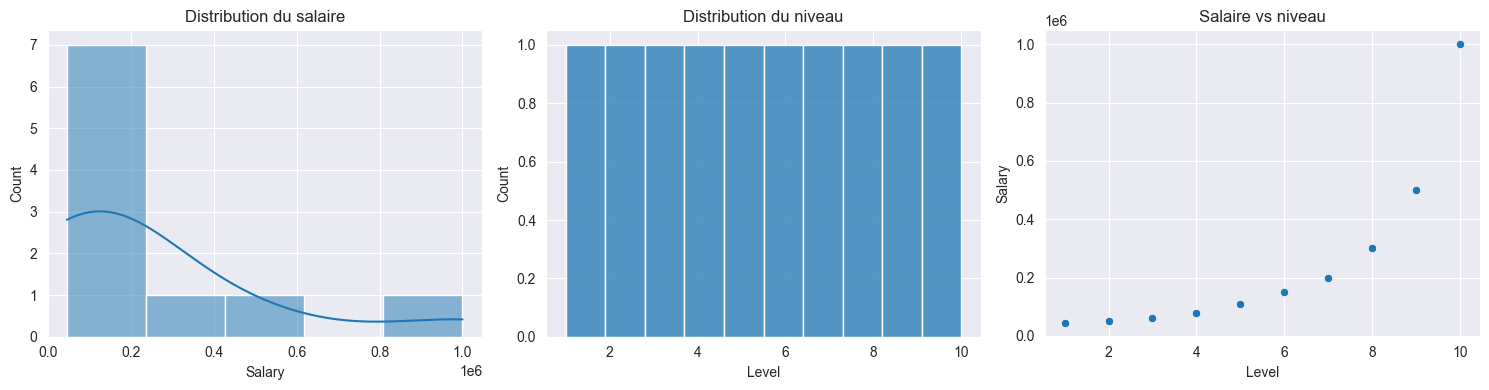

In [2]:
# b) Distribution et relation
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_sal['Salary'], kde=True, ax=ax[0]); ax[0].set_title("Distribution du salaire")
sns.histplot(df_sal['Level'], bins=10, ax=ax[1]);   ax[1].set_title("Distribution du niveau")
sns.scatterplot(data=df_sal, x='Level', y='Salary', ax=ax[2]); ax[2].set_title("Salaire vs niveau")
plt.tight_layout();
plt.show()

Ce qu’on observe (jeu classique) :

Description : 10 lignes, 3 colonnes (Position texte, Level entier de 1 à 10, Salary entier), sans valeur manquante. Position et Level portent la même information (un niveau par poste), donc on n’utilise que Level.
Salaires très étalés : de 45 000 à 1 000 000, avec une moyenne d’environ 249 500 très supérieure à la médiane (130 000). Distribution fortement asymétrique à droite, tirée par le CEO.
Niveaux uniformes : un seul exemple par niveau, donc la distribution de Level est plate.
Relation clairement non linéaire : les salaires augmentent lentement aux bas niveaux (45 000 à 150 000 entre les niveaux 1 et 6), puis explosent (200 000, 300 000, 500 000, 1 000 000). La courbe est convexe, de type exponentielle. Une droite ne conviendra pas : d’où la régression polynomiale.
Très peu de données : seulement 10 points, dont un extrême (le CEO).

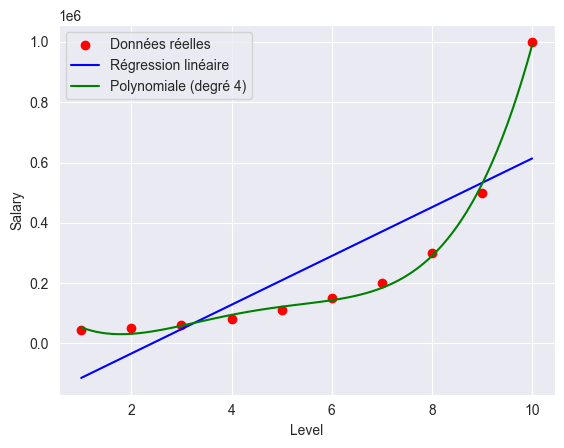

In [3]:
X = df_sal.iloc[:, 1:-1].values
y = df_sal.iloc[:, -1].values

lr = LinearRegression().fit(X, y)

pr = PolynomialFeatures(degree=4)
X_poly = pr.fit_transform(X)
lr_2 = LinearRegression().fit(X_poly, y)

# a) Courbes de prédiction (grille fine pour une courbe lisse)
X_grid = np.arange(X.min(), X.max() + 0.01, 0.1).reshape(-1, 1)
plt.scatter(X, y, color='red', label='Données réelles')
plt.plot(X_grid, lr.predict(X_grid), color='blue', label='Régression linéaire')
plt.plot(X_grid, lr_2.predict(pr.transform(X_grid)), color='green', label='Polynomiale (degré 4)')
plt.xlabel("Level"); plt.ylabel("Salary"); plt.legend(); plt.show()


In [4]:
# b) Prédiction pour Level = 7.5
print('Linéaire    :', lr.predict([[7.5]]))
print('Polynomiale :', lr_2.predict(pr.transform([[7.5]])))

# Mesure de la précision (sur les données d'apprentissage)
from sklearn.metrics import r2_score, mean_squared_error
for nom, pred in [("Linéaire", lr.predict(X)), ("Polynomiale", lr_2.predict(X_poly))]:
    print(nom, "R² =", r2_score(y, pred), "RMSE =", np.sqrt(mean_squared_error(y, pred)))

Linéaire    : [411257.57575758]
Polynomiale : [225126.29297784]
Linéaire R² = 0.6690412331929895 RMSE = 163388.73519272613
Polynomiale R² = 0.9973922891706614 RMSE = 14503.23490962701


Interprétation :

Régression linéaire : mauvais ajustement. La droite passe au-dessus des petits niveaux (elle prédit même des salaires négatifs vers les niveaux 1 et 2) et sous le CEO. Pour 7,5, elle prédit environ 411 000, bien trop haut.
Polynomiale de degré 4 : elle épouse presque tous les points, avec un R² de 0,997. Elle prédit environ 225 000 pour le niveau 7,5.
Quelle prédiction est la plus juste ? Le niveau 7,5 se situe entre Partner (niveau 7, 200 000) et Senior Partner (niveau 8, 300 000). Un salaire d’environ 250 000 serait attendu en interpolant. La polynomiale (225 000) est donc proche et plausible, la linéaire (411 000) est à côté.
Le degré 3 (241 000) est ici encore plus proche de ce repère, avec un R² de 0,981.

Limites à écrire dans le rapport
Risque de surapprentissage : avec seulement 10 points et 5 paramètres (degré 4), un R² de 0,997 n’est pas surprenant. Il est mesuré sur les données d’apprentissage, donc optimiste.
Pas de jeu de test : avec 10 points, un découpage train/test n’a pas de sens. On peut utiliser une validation croisée « leave-one-out » pour comparer les degrés, ce qui est plus rigoureux.
Extrapolation dangereuse : un polynôme de degré élevé peut osciller et donner n’importe quoi hors de [1, 10].

In [6]:
#Pour comparer les degrés proprement

from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, LeaveOneOut
for d in range(1, 7):
    m = make_pipeline(PolynomialFeatures(d), LinearRegression())
    s = cross_val_score(m, X, y, cv=LeaveOneOut(), scoring='neg_mean_squared_error')
    print(d, np.sqrt(-s.mean()))

1 231160.81061512016
2 162052.81249418296
3 114815.1357700558
4 73832.24474023603
5 38402.488291874295
6 38891.47454985291


       RMSE_train    RMSE_LOO   MAE_train     MAE_LOO  R2_train  R2_LOO    pred_7_5
degre                                                                              
1      163388.735  231160.811  128454.545  170556.185     0.669   0.338  411257.576
2       82212.124  162052.812   70218.182  120223.572     0.916   0.674  328672.348
3       38931.504  114815.136   34790.210   83137.036     0.981   0.837  240915.355
4       14503.235   73832.245   12681.818   49042.999     0.997   0.932  225126.293
5        4047.503   38402.488    3360.839   23595.209     1.000   0.982  237446.005
6        2018.778   38891.475    1476.457   21921.291     1.000   0.981  242200.643
7        1361.643   84246.967    1025.381   45122.110     1.000   0.912  242979.446
8         724.242  227342.227     531.798  117031.746     1.000   0.359  241920.035
9           0.000  264448.177       0.000  114419.776     1.000   0.133  240179.520
Meilleur degré (RMSE LOO minimal) : 5


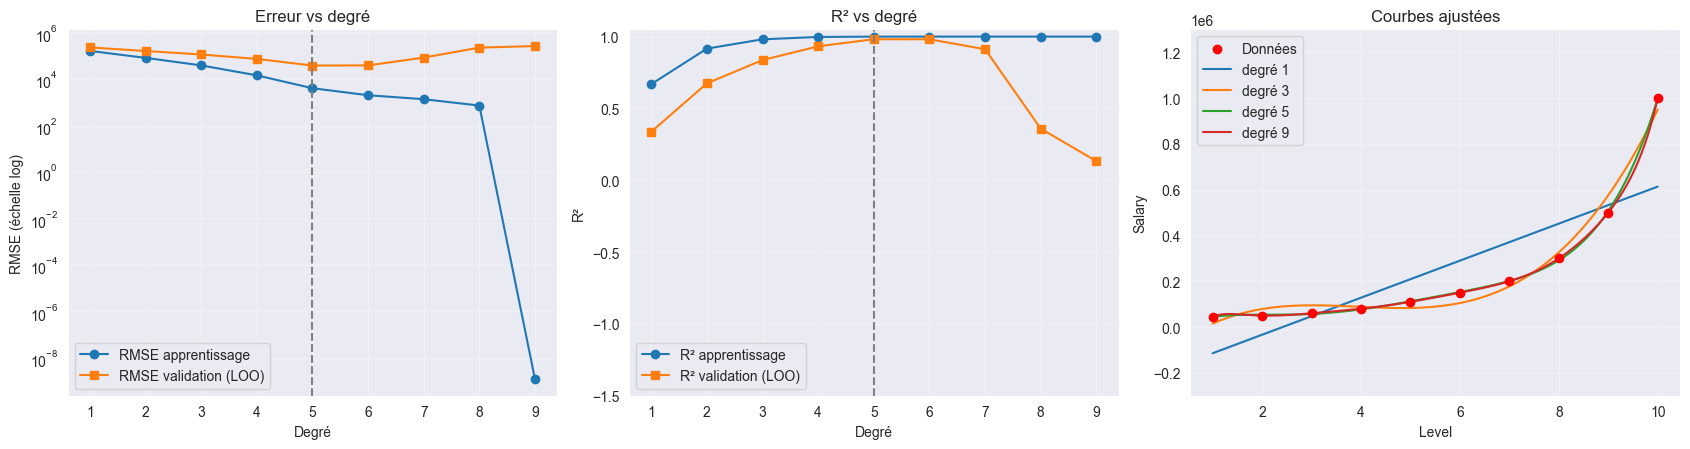

In [7]:
# ---- Choix du degré : erreur d'apprentissage vs validation (leave-one-out) ----
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def model(d):   # StandardScaler : évite l'instabilité numérique des puissances élevées
    return make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression())

rows = []
for d in range(1, 10):                      # degré max = 9 (10 points -> 10 paramètres)
    m = model(d).fit(X, y)
    ytr = m.predict(X)
    ycv = cross_val_predict(model(d), X, y, cv=LeaveOneOut())
    rows.append(dict(degre=d,
        RMSE_train=np.sqrt(mean_squared_error(y, ytr)), RMSE_LOO=np.sqrt(mean_squared_error(y, ycv)),
        MAE_train=mean_absolute_error(y, ytr),          MAE_LOO=mean_absolute_error(y, ycv),
        R2_train=r2_score(y, ytr),                      R2_LOO=r2_score(y, ycv),
        pred_7_5=m.predict([[7.5]])[0]))
res = pd.DataFrame(rows).set_index("degre")
print(res.round(3).to_string())
print("Meilleur degré (RMSE LOO minimal) :", res.RMSE_LOO.idxmin())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
best = res.RMSE_LOO.idxmin()

ax[0].plot(res.index, res.RMSE_train, 'o-', label="RMSE apprentissage")
ax[0].plot(res.index, res.RMSE_LOO, 's-', label="RMSE validation (LOO)")
ax[0].axvline(best, ls='--', c='gray'); ax[0].set_yscale('log')
ax[0].set_xlabel("Degré"); ax[0].set_ylabel("RMSE (échelle log)")
ax[0].set_title("Erreur vs degré"); ax[0].legend()

ax[1].plot(res.index, res.R2_train, 'o-', label="R² apprentissage")
ax[1].plot(res.index, res.R2_LOO, 's-', label="R² validation (LOO)")
ax[1].axvline(best, ls='--', c='gray'); ax[1].set_ylim(-1.5, 1.05)
ax[1].set_xlabel("Degré"); ax[1].set_ylabel("R²")
ax[1].set_title("R² vs degré"); ax[1].legend()

grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
ax[2].scatter(X, y, c='red', zorder=5, label="Données")
for d in (1, 3, 5, 9):
    ax[2].plot(grid, model(d).fit(X, y).predict(grid), label=f"degré {d}")
ax[2].set_ylim(-3e5, 1.3e6)
ax[2].set_xlabel("Level"); ax[2].set_ylabel("Salary")
ax[2].set_title("Courbes ajustées"); ax[2].legend()

for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

NB : on utilise leave one out par ce que le jeu de données est trop petit --> on entraine sur 9 points et on teste sur 1.